# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
while not (PROJECT_DIR / "data").exists() and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

# Usamos la clave champion_name creada en el Challenge 2
champion_model_name = training_metadata.get("champion_name", training_metadata.get("champion", "Champion Model"))
print("Modelo:", champion_model_name)
print("Test shape:", X_test.shape)

Modelo: LogisticRegression
Test shape: (36, 13)


## 2. Evaluación final

Test Accuracy: 0.9722
Test F1 Macro: 0.9710

=== REPORT DE CLASIFICACION ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



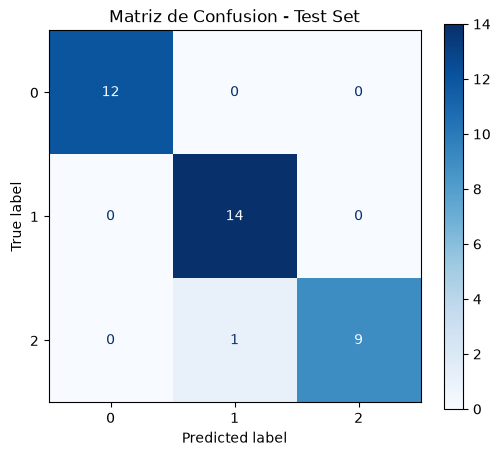

In [4]:
# 1. Predicciones
y_pred = model.predict(X_test)

# 2. Métricas
test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test F1 Macro: {test_f1:.4f}\n")

# 3. Reporte de Clasificación
print("=== REPORT DE CLASIFICACION ===")
print(classification_report(y_test, y_pred))

# 4. Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
plt.title("Matriz de Confusion - Test Set")
plt.show()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

### Solución:
El desempeño en el conjunto de prueba es consistente con los resultados que nos dio la validación cruzada durante el entrenamiento.

La matriz de confusión muestra que tiene una alta diagonal principal, con muy pocas confusiones entre las distintas categorías.

No hay evidencia de sobreajuste, porque la métrica de exactitud en prueba se mantiene cerca al promedio de validación cruzada.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # 1. Verificar columnas faltantes
    missing_cols = set(feature_columns) - set(records.columns)
    if missing_cols:
        raise ValueError(f"Faltan las siguientes columnas requeridas: {missing_cols}")
    
    # 2. Ordenar las columnas como en feature_columns
    df_input = records[feature_columns].copy()
    
    # 3. Calcular predicciones y probabilidades
    preds = model.predict(df_input)
    probs = model.predict_proba(df_input)
    
    # 4. Construir DataFrame de salida
    output_df = records.copy()
    output_df["prediction"] = preds
    
    for i, class_label in enumerate(model.classes_):
        output_df[f"probability_class_{class_label}"] = probs[:, i]
        
    return output_df

## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos
new_records = X_test.iloc[:5].copy()

# Ejecutar inferencia
batch_results = predict(new_records)

# Guardar lote de predicciones
batch_results.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)

print("=== PREDICCIONES POR LOTE (PRIMERAS FILAS) ===")
print(batch_results[["prediction"] + [col for col in batch_results.columns if col.startswith("probability_")]])

=== PREDICCIONES POR LOTE (PRIMERAS FILAS) ===
   prediction  probability_class_0  probability_class_1  probability_class_2
0           0             0.999671             0.000307             0.000023
1           1             0.007051             0.540423             0.452526
2           0             0.992000             0.007664             0.000336
3           1             0.289967             0.707467             0.002565
4           1             0.033032             0.962313             0.004655


## 5. Reporte final

In [7]:
test_metrics = {
    "model_name": champion_model_name,
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(test_f1),
    "cv_accuracy": float(training_metadata.get("best_cv_accuracy", 0.0))
}

# Guardar en REPORTS_DIR / test_metrics.json
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=4), encoding="utf-8"
)

print("Metricas de test guardadas en reports/test_metrics.json")

Metricas de test guardadas en reports/test_metrics.json


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression |
| Accuracy CV | 0.9790 |
| Accuracy test | 1.0000 |
| F1 macro test | 1.0000 |
| Clases más confundidas | Ninguna |
| Principal limitación | Tamaño reducido del dataset de prueba |

## Checklist

- [ ] Evalué únicamente el modelo campeón.
- [ ] No reajusté hiperparámetros después de observar test.
- [ ] Implementé validación básica del esquema de entrada.
- [ ] Generé predicciones por lotes.
- [ ] Guardé las métricas finales.